# Q-learning

In [2]:
import time 
import gymnasium as gym
from tqdm import tqdm  # tqdm es una libreria que muestra barra de progresos
import random
import numpy as np 
import matplotlib.pyplot as plt

print(gym.__version__)

1.3.0


In [3]:
# Crear ambiente 
env = gym.make('CliffWalking-v1', render_mode = 'human')
# Probando un episodio
observation, _ = env.reset() 
done = False
for _ in range(20):
    #Escoger una acción random
    action = env.action_space.sample()  
    #Usar la acción en el ambiente
    observation, reward, terminated, truncated, info = env.step(action) 
    done = terminated or truncated

#Cerrar el ambiente    
env.close()

In [4]:
class QLearning:
    """ Q-learning algorithm """
    def __init__(self, epsilon, epsilon_min, epsilon_decay, alpha, gamma, n_states, n_action):
        self.Q_table = np.zeros([n_states, n_action])  # Inicializar Q(s,a) table
        self.n_action = n_action  # numero de acciones
        self.alpha = alpha  # tasa de aprendizaje
        self.gamma = gamma  # factor de descuento
        self.epsilon = epsilon  # Parametros epsilon-greedy 
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay

    def take_action(self, state):  # epsilon-greedy seleccion de acciones
        if np.random.random() < self.epsilon:
            action = np.random.randint(self.n_action)
        else:
            action = np.argmax(self.Q_table[state])
        return action

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon*self.epsilon_decay)

    def best_action(self, state):  # para imprimir la estrategia
        Q_max = np.max(self.Q_table[state])
        a = [0 for _ in range(self.n_action)]
        for i in range(self.n_action):
            if self.Q_table[state, i] == Q_max:
                a[i] = 1
        return a

    def update(self, s0, a0, r, s1):
        td_error = r + self.gamma * self.Q_table[s1].max() - self.Q_table[s0, a0]
        self.Q_table[s0, a0] += self.alpha * td_error

Iteration 9: 100%|██████████| 200/200 [00:00<00:00, 3032.29it/s, episode=2000, return=-13.000, epsilon=0.010]


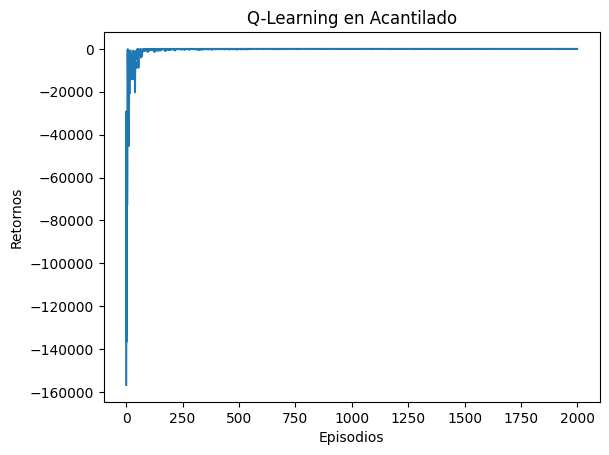

In [5]:
env = gym.make('CliffWalking-v1')

n_states = env.observation_space.n
n_actions = env.action_space.n
np.random.seed(0)
epsilon = 1
epsilon_min = 0.01
epsilon_decay = 0.995
alpha = 0.5
gamma = 0.99
agent = QLearning(epsilon, epsilon_min, epsilon_decay, alpha, gamma, n_states, n_actions)
num_episodes = 2000  # Numero de secuencias que el agente correra el ambiente

return_list = []  # Guardar el retorno de cada secuencia
for i in range(10):  # Mostrar 10 barras de progreso
    # Barras de progreso de la funcion tdqm
    with tqdm(total=int(num_episodes / 10), desc='Iteration %d' % i) as pbar:
        for i_episode in range(int(num_episodes / 10)):  # numero de secuencias de cada barra de progreso
            episode_return = 0
            state, _ = env.reset()
            action = agent.take_action(state)
            done = False
            while not done:
                next_state, reward, terminated, truncated, _ = env.step(action)
                done = terminated or truncated
                next_action = agent.take_action(next_state)
                episode_return += reward  
                agent.update(state,action,reward,next_state)
                state = next_state
                action = next_action
            agent.decay_epsilon()
            return_list.append(episode_return)
            if (i_episode + 1) % 10 == 0:  # Imprimir el retorno promedio
                pbar.set_postfix({
                    'episode':
                    '%d' % (num_episodes / 10 * i + i_episode + 1),
                    'return':
                    '%.3f' % np.mean(return_list[-10:]),
                    'epsilon':
                    '%.3f' % agent.epsilon
                })
            pbar.update(1)

episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('Q-Learning en {}'.format('Acantilado'))
plt.show()

In [6]:
def print_agent(agent, env, action_meaning, disaster=[], end=[]):
    for i in range(env.unwrapped.shape[0]):
        for j in range(env.env.unwrapped.shape[1]):
            if (i * env.unwrapped.shape[1] + j) in disaster:
                print('****', end=' ')
            elif (i * env.unwrapped.shape[1] + j) in end:
                print('EEEE', end=' ')
            else:
                a = agent.best_action(i * env.unwrapped.shape[1] + j)
                pi_str = ''
                for k in range(len(action_meaning)):
                    pi_str += action_meaning[k] if a[k] > 0 else 'o'
                print(pi_str, end=' ')
        print()

action_meaning = ['^', '>', 'v', '<']
print('La estrategia obtenida por el algoritmo de Q-learning es：')
print_agent(agent, env, action_meaning, list(range(37, 47)), [47])

La estrategia obtenida por el algoritmo de Q-learning es：
o>vo o>vo o>vo o>vo o>vo o>vo o>vo o>vo o>vo o>vo o>vo oovo 
o>vo o>vo o>vo o>vo o>vo o>vo o>vo o>vo o>vo o>vo o>vo oovo 
o>oo o>oo o>oo o>oo o>oo o>oo o>oo o>oo o>oo o>oo o>oo oovo 
^ooo **** **** **** **** **** **** **** **** **** **** EEEE 


In [7]:
agent.Q_table

array([[ -13.99416454,  -13.12541872,  -13.12541872,  -13.99416454],
       [ -13.12541872,  -12.2478977 ,  -12.2478977 ,  -13.99416454],
       [ -12.2478977 ,  -11.36151283,  -11.36151283,  -13.12541872],
       [ -11.36151283,  -10.46617457,  -10.46617457,  -12.2478977 ],
       [ -10.46617457,   -9.5617925 ,   -9.5617925 ,  -11.36151283],
       [  -9.5617925 ,   -8.64827525,   -8.64827525,  -10.46617457],
       [  -8.64827525,   -7.72553056,   -7.72553056,   -9.5617925 ],
       [  -7.72553056,   -6.79346521,   -6.79346521,   -8.64827525],
       [  -6.79346521,   -5.85198506,   -5.85198506,   -7.72553056],
       [  -5.85198506,   -4.90099501,   -4.90099501,   -6.79346521],
       [  -4.90099501,   -3.940399  ,   -3.940399  ,   -5.85198506],
       [  -3.940399  ,   -3.940399  ,   -2.9701    ,   -4.90099501],
       [ -13.99416454,  -12.2478977 ,  -12.2478977 ,  -13.12541872],
       [ -13.12541872,  -11.36151283,  -11.36151283,  -13.12541872],
       [ -12.2478977 ,  -10.466174

In [8]:
#Reto 5
#'Usando el agente entrenado'
#Crea el código necesario para que el
#agente entrenado juegue un episodio
#en al ambiente. Imprime en pantalla
#cada paso de tiempo del ambiente.

#Obtener estado inicial
env = gym.make('CliffWalking-v1', render_mode = 'human')
state, _ = env.reset()

for step in range(100):
    #Escoger la mejor acción de la q_table
    action = np.argmax(agent.Q_table[state])
    #Obtener s', r', donde e info
    state, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    
    if done:
        break

#Cerrar ambiente        
env.close()